In [1]:
# Langkah 1 - Buat Dataset Dummy
import numpy as np
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False, random_state=42)

# Mengubah ke nilai integer non-negatif
X = np.absolute(X)
X = np.round(X, 2) * 100
X = X.astype(int)

print("Fitur X (10 baris pertama):\n", X[:10])
print("\nLabel y:\n", y)

Fitur X (10 baris pertama):
 [[112 139]
 [179 210]
 [ 83  71]
 [182 265]
 [105  78]
 [ 67  43]
 [ 36  54]
 [ 20  70]
 [122  70]
 [250  83]]

Label y:
 [0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [2]:
# Langkah 2 & 3 - Membuat DataFrame & Labeling Kategorial
import pandas as pd

y_new = y.reshape(len(y), 1)
data = np.concatenate((X, y_new), axis=1)
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']
df = pd.DataFrame(data, columns=nama_kolom)

labels = {1: 'Kelas A', 0: 'Kelas B'}
df_label = df.copy()
df_label['Label'] = df_label['Label'].astype(int).map(labels)
display(df_label.head())

,Fitur 1,Fitur 2,Label
0,112,139,Kelas B
1,179,210,Kelas B
2,83,71,Kelas B
3,182,265,Kelas B
4,105,78,Kelas B


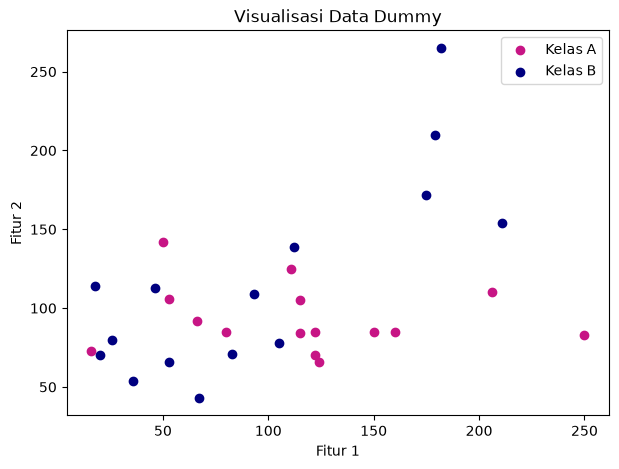

In [3]:
# Langkah 4 - Visualisasi Data
import matplotlib.pyplot as plt

colors = {'class_a': 'MediumVioletRed', 'class_b': 'Navy'}
class_a = df_label[df_label['Label'] == 'Kelas A']
class_b = df_label[df_label['Label'] == 'Kelas B']

plt.figure(figsize=(7, 5))
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'], label='Kelas A')
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'], label='Kelas B')
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.title('Visualisasi Data Dummy')
plt.legend()
plt.show()

In [4]:
# Langkah 5 - Model Multinomial Naive Bayes
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

mnb = MultinomialNB()
mnb.fit(X_train, y_train)

y_train_pred = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Hasil akurasi data train (Multinomial): {acc_train:.4f}')
print(f'Hasil akurasi data test  (Multinomial): {acc_test:.4f}')

Hasil akurasi data train (Multinomial): 0.8095
Hasil akurasi data test  (Multinomial): 0.3333


In [5]:
# Langkah 6 - Model Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

y_train_pred_gnb = gnb.predict(X_train)
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

y_test_pred_gnb = gnb.predict(X_test)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb:.4f}')
print(f'Hasil akurasi data test  (Gaussian): {acc_test_gnb:.4f}')

Hasil akurasi data train (Gaussian): 0.8571
Hasil akurasi data test  (Gaussian): 0.4444
